# Higher-upside models: results, decisions and reproduction

This notebook reviews six structural pilots: four scratch TabM recipes and
two learned-feature CatBoost recipes. The previous submitted file has confirmed
public AUC **0.76824**. The target **0.8+** is aspirational; another entrant's
score does not establish what these allowed inputs can achieve. No external
data, recovered labels or pretrained weights are used.

All ten notebooks that preceded this modeling phase are unchanged. Notebook
08 recorded the procedure before these pilots. All trial evidence, including
failures and negative results, is retained.

In [1]:
from pathlib import Path
import sys,json,hashlib,subprocess
import numpy as np,pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'input/train.csv').exists())
assert Path(sys.prefix).resolve()==(ROOT/'.venv').resolve()
HERE=ROOT/'improvements/high_upside';ART=HERE/'artifacts'
read=lambda p:json.loads(p.read_text())
records=read(ART/'model_experiment_ledger.json')
final=read(ART/'model_final_results.json')
print('Python:',sys.executable)
display(pd.Series(final))
display(Markdown((HERE/'MODELING_PLAN.md').read_text()))
display(Markdown((HERE/'ACCELERATOR_AMENDMENT.md').read_text()))
display(Markdown((HERE/'COMPLEXITY_POLICY.md').read_text()))
display(read(ART/'model_preflight.json'))

Python: /Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python


accepted                                                               True
new_submission_created                                                 True
submission                                output/submission_high_upside.csv
sha256                    15d050aa8709ae4e2d338b013c03216d4b3f3279348a3f...
public_score                                                           None
rows                                                                  61500
full_oof                  {'auc': 0.766714324202899, 'average_precision'...
full_oof_independent                                                  False
new_models                                                               30
baseline_models                                                          75
probability_min                                                    0.002045
probability_max                                                    0.772346
probability_mean                                                   0.088953
recommendati

# Higher-upside model pilots and submission gates

Recorded before fitting these candidates. The user has authorized continuing
through training, validation and a submission decision. The prior incremental
round-four controller stays stopped. Current reference is the public-confirmed
round-three bagged CSV (0.76824). No external rows or pretrained weights.

## Six structural pilots

Four scratch TabM recipes: raw inputs with piecewise-linear numerical embeddings;
the successful signed 55-column frame with the same recipe; that frame with
periodic numerical embeddings; and a more regularized full TabM recipe. The first
three use the efficient mini architecture. Common settings: 16 internal members,
128 hidden units, two blocks, eight-dimensional embeddings, AdamW, batch 1,024,
cosine learning-rate schedule, up to 140 epochs, 20-epoch AUC patience. Regularized
recipe uses 180 epochs, learning rate .001 versus .002, dropout .25 versus .10,
and weight decay .003 versus .0003. These are combined recipes; that comparison
does not identify a single parameter effect. Numerical medians/quantile transforms,
category vocabularies, nonconstant column selection and embedding bins fit training
rows only. Explicit numerical missing flags are included. Unknown categories get
a reserved category. Each member's BCE is optimized independently; inference
averages probabilities, as the authors specify.

Two CatBoost pilots hold the successful family settings (depth5, l2=8,
random_strength=.5, learning_rate=.045, max4,500 trees, patience200) fixed:

1. Add three fold-safe reconstructed external scores and observed-score residuals.
   Auxiliary LightGBM regressors use only supplied feature columns, exclude their
   predicted score column and TARGET/ID, and train on observed auxiliary targets.
   Training-row reconstructions are three-fold OOF; validation/test reconstructions
   use regressors fitted only on the outer training rows. Missingness is retained.
   Save auxiliary OOF R2 on observed rows; positive auxiliary R2 is not sufficient
   for acceptance and may not transfer to truly missing cases.
2. Add smoothed cross-fitted risk encodings for predeclared borrower/loan/score
   interactions. Five inner folds generate training encodings; full outer-train
   maps encode validation/test. Two prior strengths (30,100) and support/frequency
   features are a block, not individually selected. Outer validation labels are
   absent from every map and every fit. Cut edges fit only outer training inputs.

Exact specs are written to `artifacts/model_candidate_plan.json` before fitting.
No source edits to the fitting core while any fit process is running. Include
actual source/data/split/package hashes in cache identities. Neural processes use
one OpenMP library via DYLD_LIBRARY_PATH on this Mac; do not suppress duplicate
runtime detection with KMP_DUPLICATE_LIB_OK. Hardware currently exposes CPU only.
Save learning curves, timings, seeds, versions, failures and full predictions.

## Compute allocation and progression

Use the original repeatedly explored inner split to screen all six. Limit each
neural pilot to 25 minutes; stop at the best completed epoch if reached and label
the truncation. This is not a negative claim about an unconverged model. Run neural
models sequentially with four CPU threads. Fit no more than two finalists in
primary common-five-fold development CV: best neural and best learned-feature
CatBoost, each needing >=0.00030 screened blend gain over the entire reference.
Probe new-family weights .10,.25,.50,.75,1.00. If a neural model is truncated before
15 epochs without a useful gain, do not expand it. No random broad sweep.

For the finalists, compare on the original primary five folds (SEED+2). Search a
complete primary-only grid: reference/new and new/new pairs with weights
.10,.25,1/3,.50,2/3,.75,.90; and reference plus both helpers with reference weights
.25,.50,.75 and relative helper shares .25,.50,.75. Probability and log-odds means
only. Freeze the complete winner and fixed median epochs/iterations before any
confirmation. At most two new families.

The ambition for a substantial branch is >=0.002 OOF gain; a smaller robust gain
can still justify a candidate, but will not trigger a bigger sweep or seed bank.
Require >=0.00030 primary gain for submission eligibility. Confirmation uses
SEED+3101 (not any earlier confirmation seed), fixed counts, no validation early
stopping, frozen weights/method, positive pooled gain and >=4/5 positive groups.
Fit matching new-family OOF on the two other existing development seeds
(SEED+301,SEED+1101). Average each family before the frozen blend; require >=0.00030
gain over the complete three-seed reference plus >=4/5 positive primary groups.
These are explored development labels; new partitions are robustness checks,
not an untouched test. Public feedback does not select weights.

If no pilot reaches promotion, complete the negative-result journal and retain
the existing submission; do not create a deceptively relabeled CSV. If a family
fails a later gate, retain its evidence and stop its deployment branch.

## Submission and delivery

A passing recipe reuses the original bank and trains only needed new families on
three full-data five-fold seeds (SEED+3,+302,+602), frozen lengths, with no use of
held-out labels for stopping. Write `output/submission_high_upside.csv`; preserve
all previous CSVs. Reproduce from saved models byte-for-byte, check all61,500 IDs,
schema, finiteness and score range. Full-data OOF is diagnostic and does not retune.
Document the exact score provenance and avoid claiming 0.8 without an actual
submitted score. Create new notebooks only; execute them with the local venv.
Update the report/journal and create a new verified reproduction archive if a new
submission is accepted. Even a failed branch gets executed result documentation.

## References

Methods/code only: https://github.com/yandex-research/tabm and its documented
numerical-embedding dependency. Installed package licenses/versions are recorded.
No repository datasets, pretrained models, original Home Credit tables or labels
are imported. These method references do not predict a gain on this competition.


# Prospective local-GPU amendment

Timing: after the first three CPU pilots completed, before the regularized neural
pilot completed and before any primary CV, recipe selection or confirmation.
No score gate, candidate hyperparameter or weight grid changes.

The sandbox reported MPS unavailable. A separate local hardware check outside the
sandbox reported MPS available. A randomly initialized representative network
measured 0.10265 seconds/batch on CPU and 0.03308 on MPS, approximately three times
faster. This is a throughput probe, not a competitive model or dataset.
`artifacts/model_neural_hardware_check.json` records the result.

The CPU worker and waiting delivery worker were stopped. The first three complete
CPU model/prediction/curve/metric artifacts remain byte-identical; their hashes,
specs, original identity and reuse reason are recorded in
`reference/cpu_stage_reuse.json`. The interrupted regularized model has no final
pilot record and is not counted as a scientific negative. Its partial learning
curve and the original runner/logs are preserved under `reference/cpu_stage`.

New `h_accel.py` trains subsequent neural fits on the local MPS GPU. It reuses the
unchanged encoder, feature functions and predictor classes from the original
fitting core. Initial weights and shuffle order are seeded on CPU, with MPS seeded
too. Architecture, losses, optimizer, learning-rate schedule, stopping budgets and
validation gates remain those in the original plan. Trees and preprocessing remain
on CPU. GPU validation can have small float32 differences; retained predictions
and all saved-model inference are generated on CPU. Exact saved-weight replay on
CPU is checked; bit-identical GPU retraining is not promised.

The current engine identity includes the separately hashed GPU implementation and
this amendment. Historical CPU pilot results retain their original signatures.
They are reused only as recorded stage evidence after checking their complete
artifact hashes, exact specs, unchanged original core/data/package identity and
explicit CPU diagnostics. They are not silently relabeled as GPU results or
asserted to equal a new GPU fit. All new CV/final results use the new identity.

This mixed-hardware pilot stage compares complete recipes. It does not isolate
architecture or regularization effects from hardware numerical differences.
All newly selected families are validated on the same current backend through
the unchanged downstream gates. Source/recipe freezes still precede confirmation.
No outside data, cloud resources, pretrained weights or transfers are involved.


# Budget-aware recipe selection, before freeze and confirmation

Timing: the neural primary CV and a read-only neural/reference pair preview were
complete; tree primary CV was still running. The complete joint grid, selected
recipe and any confirmation results had not been observed. Both workers were
stopped before changing the selection controller. The original runner/log/state
are preserved under `reference/before_complexity_policy`. Completed fits remain
unchanged, and no fitting source, hyperparameter, data or cached prediction changes.

The user explicitly prioritized larger steps over spending time on negligible
improvements. Apply this additional compute-allocation rule to the already-declared
primary grid: a recipe using two new families must gain **at least 0.00030 AUC**
over the best recipe using at most one new family. Otherwise choose the best
one-family addition. The reference alone is eligible as the simpler candidate.
The rule controls future training cost; it is not a significance test.

Keep the entire unconstrained grid, its maximum, the simpler maximum and the
incremental contribution in the selection record. Do not erase a more complex
candidate's score or the tree finalist's CV. Existing overall >=0.00030 eligibility,
fresh confirmation and matching-three-seed gates remain unchanged. No new methods,
weights or family configurations are introduced. The chosen recipe is frozen
before any confirmation; no simplification or reweighting occurs afterwards.

Fit cache identities stay unchanged because fitting code/inputs are unchanged.
The selection freeze additionally hashes this policy and amended controller.
Cold reproduction therefore applies the same explicit budget-aware rule.
This amendment is an adaptive budget decision with its timing recorded, rather
than presented as part of the original pre-pilot plan.


{'passed': True,
 'signature': 'fd4bd07beac5036482fe45fa854ed47d1e981739c35a88e7d7ea98a32153eb42',
 'feature_target_id_independence': True,
 'train_test_schema': True,
 'neural_saved_model_replay_exact': True,
 'neural_batch_max_difference': 2.9802322387695312e-08,
 'unknown_category_reserved': True,
 'learned_transform_batch_invariance': True,
 'auxiliary_software_probe': {'score_reconstruction': {'EXT_SOURCE_1': {'observed_rows': 341,
    'auxiliary_oof_r2': 0.25237476992076346},
   'EXT_SOURCE_2': {'observed_rows': 1198,
    'auxiliary_oof_r2': 0.09835271965101033},
   'EXT_SOURCE_3': {'observed_rows': 803,
    'auxiliary_oof_r2': -0.023918244457870053}},
  'interaction_risk': {'inner_folds': 5, 'interactions': 8, 'features': 32}},
 'prior_75_model_replay_max_difference': 1.1102230246251565e-16,
 'python': '/Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python',
 'training_backend': 'mps',
 'inference_backend': 'cpu',
 'gpu_cpu_prediction_max_diffe

## Standalone strength and ensemble contribution

Every pilot uses the same explored inner split and the complete reference
mixture. Its five blend probes are saved, including pure new-model weight 1.
A weaker standalone model can contribute complementary ranking errors. A
small screen gain still needs common-fold CV and fixed-weight confirmation.
Software probes do not count as competitive configurations.

,name,kind,auc,blend_gain,retained_count,seconds,status,promoted
1,hu_tabm_signed_piecewise,tabm,0.750805,0.001539,30,366.760852,complete,True
3,hu_tabm_regularized,tabm,0.750147,0.000979,37,263.084396,complete,False
2,hu_tabm_signed_periodic,tabm,0.748198,0.000918,37,442.014464,complete,False
4,hu_cat_score_reconstruction,cat,0.750757,0.000366,1217,112.701118,complete,True
0,hu_tabm_raw_piecewise,tabm,0.740111,0.000239,28,278.632492,complete,False
5,hu_cat_interaction_risk,cat,0.745380,-0.000133,991,99.310267,complete,False


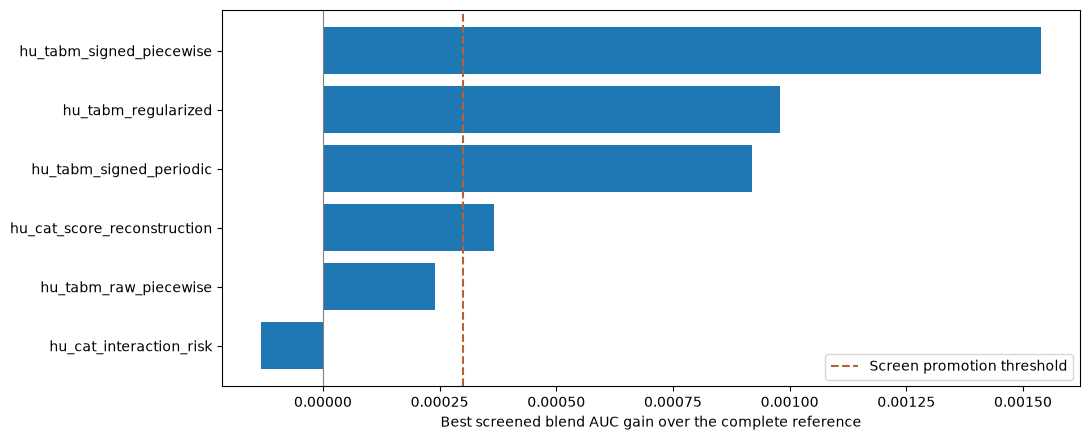

In [2]:
rows=pd.DataFrame([dict(name=a['name'],kind=a['kind'],auc=a['auc'],blend_gain=a['delta'],
    retained_count=a['count'],seconds=a['seconds'],status=a['status'],promoted=a['promoted']) for a in records])
display(rows.sort_values('blend_gain',ascending=False))
valid=rows[rows.status=='complete'].sort_values('blend_gain')
if len(valid):
    fig,ax=plt.subplots(figsize=(11,4.5));ax.barh(valid['name'],valid['blend_gain'])
    ax.axvline(0,color='gray',linewidth=.8);ax.axvline(.0003,color='#b56336',linestyle='--',label='Screen promotion threshold')
    ax.set_xlabel('Best screened blend AUC gain over the complete reference')
    ax.legend();fig.tight_layout();fig.savefig(ART/'model_screen_gains.png',dpi=140);plt.show()

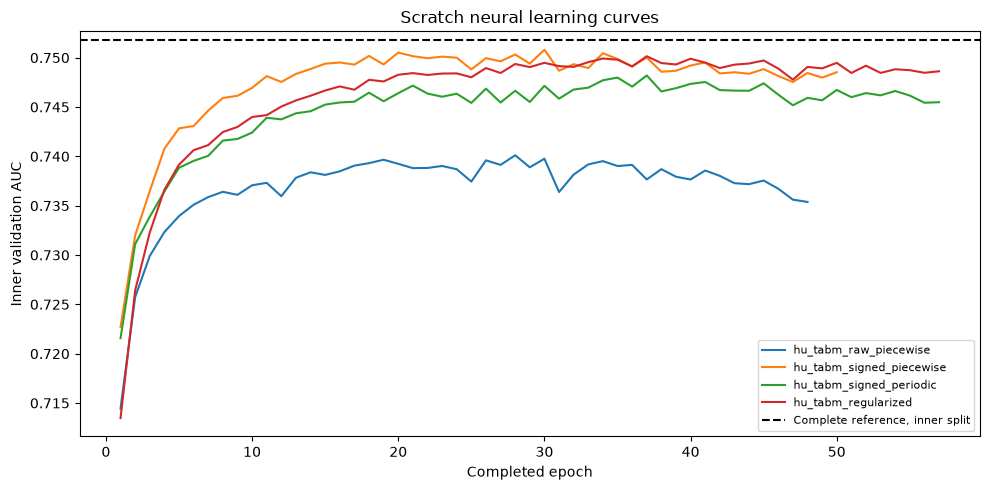

In [3]:
fig,ax=plt.subplots(figsize=(10,5));drawn=False
for a in records:
    if a['kind']!='tabm' or a['status']!='complete':continue
    curve=read(ART/'pilots'/(a['name']+'_curve.json'))
    ax.plot([r['epoch'] for r in curve],[r['validation_auc'] for r in curve],label=a['name'])
    drawn=True
if drawn:
    reference=next(a['reference_auc'] for a in records if a['status']=='complete')
    ax.axhline(reference,color='black',linestyle='--',label='Complete reference, inner split')
    ax.set(xlabel='Completed epoch',ylabel='Inner validation AUC',title='Scratch neural learning curves')
    ax.legend(fontsize=8);fig.tight_layout();fig.savefig(ART/'model_neural_curves.png',dpi=140);plt.show()
else:plt.close(fig)

## Why each experiment was retained or rejected

Auxiliary reconstruction R2 is evaluated on observed external scores; it does
not measure ranking gains or guarantee quality on genuinely missing scores.
Interaction-risk maps use inner OOF targets for training features and full
outer-training maps for validation/test features. Each outer validation label
is excluded from every transformation and fit. Time-capped neural fits are
explicitly distinguished from converged negative results.

In [4]:
for a in records:
    display(Markdown('### '+a['name']+'\n\n'+a['hypothesis']+'\n\n'+a['interpretation']))
    display(a['spec']);display(a['diagnostics'])
    if a['cv']:display({k:v for k,v in a['cv'].items() if k not in ['spec','signature']})
display(read(ART/'model_promotion.json'))

### hu_tabm_raw_piecewise

Numerical embeddings and joint shared-weight ensembling on supplied raw predictors.

Standalone inner AUC 0.7401112; best blend gain +0.0002394 against the complete current reference. Did not advance under the recorded promotion rule. Retained epoch 28 of 48 completed; stopping reason: AUC patience. This tests this embedding/shared-ensemble recipe, not all neural architectures. A time-truncated fit cannot rule out useful convergence. Mechanisms are hypotheses, not causal findings. Repeatedly explored selection labels cannot establish hidden-test improvement.

{'kind': 'tabm',
 'architecture': 'tabm-mini',
 'dropout': 0.1,
 'learning_rate': 0.002,
 'weight_decay': 0.0003,
 'max_epochs': 140,
 'patience': 20,
 'max_seconds': 1500,
 'name': 'hu_tabm_raw_piecewise',
 'features': 'raw',
 'embedding': 'piecewise',
 'hypothesis': 'Numerical embeddings and joint shared-weight ensembling on supplied raw predictors.'}

{'stop_reason': 'AUC patience',
 'epochs_completed': 48,
 'parameters': 88032,
 'numeric_dimensions': 34,
 'categorical_cardinalities': [3, 4, 9, 6, 7, 7, 20, 59],
 'device': 'cpu',
 'source_hashes': {'h_models.py': 'ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461',
  'h_features.py': '47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42'}}

### hu_tabm_signed_piecewise

Same neural recipe with the successful tree representation.

Standalone inner AUC 0.7508052; best blend gain +0.0015386 against the complete current reference. Promoted to common-fold CV. Retained epoch 30 of 50 completed; stopping reason: AUC patience. This tests this embedding/shared-ensemble recipe, not all neural architectures. A time-truncated fit cannot rule out useful convergence. Mechanisms are hypotheses, not causal findings. Repeatedly explored selection labels cannot establish hidden-test improvement.

{'kind': 'tabm',
 'architecture': 'tabm-mini',
 'dropout': 0.1,
 'learning_rate': 0.002,
 'weight_decay': 0.0003,
 'max_epochs': 140,
 'patience': 20,
 'max_seconds': 1500,
 'name': 'hu_tabm_signed_piecewise',
 'features': 'signed',
 'embedding': 'piecewise',
 'hypothesis': 'Same neural recipe with the successful tree representation.'}

{'stop_reason': 'AUC patience',
 'epochs_completed': 50,
 'parameters': 136608,
 'numeric_dimensions': 64,
 'categorical_cardinalities': [3, 4, 9, 6, 7, 7, 20, 59, 9, 5],
 'device': 'cpu',
 'source_hashes': {'h_models.py': 'ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461',
  'h_features.py': '47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42'}}

... (11 outputs left out)

### hu_cat_interaction_risk

Use regularized OOF borrower/loan/score interaction risks to expose nonlinear population structure.

Standalone inner AUC 0.7453797; best blend gain -0.0001325 against the complete current reference. Did not advance under the recorded promotion rule. Inner OOF risk maps prevent direct own-target encoding; their extra supervised representation can still add noise, selection bias or redundant signal already available to CatBoost. Mechanisms are hypotheses, not causal findings. Repeatedly explored selection labels cannot establish hidden-test improvement.

{'name': 'hu_cat_interaction_risk',
 'kind': 'cat',
 'features': 'signed',
 'learned': 'interaction_risk',
 'params': {'depth': 5, 'l2_leaf_reg': 8, 'random_strength': 0.5},
 'max_iterations': 4500,
 'patience': 200,
 'hypothesis': 'Use regularized OOF borrower/loan/score interaction risks to expose nonlinear population structure.'}

{'auxiliary': {'inner_folds': 5, 'interactions': 8, 'features': 32},
 'source_hashes': {'h_models.py': 'ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461',
  'h_features.py': '47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42'}}

{'chosen': [{'name': 'hu_tabm_signed_piecewise',
   'spec': {'kind': 'tabm',
    'architecture': 'tabm-mini',
    'dropout': 0.1,
    'learning_rate': 0.002,
    'weight_decay': 0.0003,
    'max_epochs': 140,
    'patience': 20,
    'max_seconds': 1500,
    'name': 'hu_tabm_signed_piecewise',
    'features': 'signed',
    'embedding': 'piecewise',
    'hypothesis': 'Same neural recipe with the successful tree representation.'},
   'origin': 'high_upside'},
  {'name': 'hu_cat_score_reconstruction',
   'spec': {'name': 'hu_cat_score_reconstruction',
    'kind': 'cat',
    'features': 'signed',
    'learned': 'score_reconstruction',
    'params': {'depth': 5, 'l2_leaf_reg': 8, 'random_strength': 0.5},
    'max_iterations': 4500,
    'patience': 200,
    'hypothesis': 'Use observed external scores as auxiliary supervised targets, with nested OOF reconstructions and residuals.'},
   'origin': 'high_upside'}],
 'threshold': 0.0003,
 'decisions': [{'name': 'hu_tabm_raw_piecewise',
   'status'

## Frozen selection, confirmation and matching seed count

The pair/helper grid, selection source, weights and median epochs/trees were
fixed before new confirmation fits. Confirmation uses fixed counts and no
validation early stopping. Matching three-seed validation averages each
family before the frozen combination method. These are robustness checks on
previously explored labels, not untouched independent tests. Failed gates
stop deployment and retain the current submission.

names                                  [round3_reference, hu_tabm_signed_piecewise, h...
weights                                                             [0.25, 0.375, 0.375]
method                                                                       probability
auc                                                                             0.765431
baseline_auc                                                                    0.763723
gain                                                                            0.001708
primary_gate_passed                                                                 True
substantial_gain                                                                   False
fold_gains                             [0.0025327478961900685, 0.0021043124935127278,...
new_families                           [{'name': 'hu_tabm_signed_piecewise', 'spec': ...
confirmation_seed                                                               20264209
grid_size            

baseline                     {'auc': 0.7627263204899741, 'average_precision...
candidate                    {'auc': 0.7642283520726878, 'average_precision...
gain                                                                  0.001502
fold_gains                   [0.001609001821388234, 0.0019942993998888214, ...
positive_folds                                                               5
passed                                                                    True
weights_retuned                                                          False
validation_early_stopping                                                False
caveat                       Fresh partition of repeatedly explored labels;...
dtype: object

baseline            {'auc': 0.7648034854637242, 'average_precision...
candidate           {'auc': 0.7662609426013722, 'average_precision...
gain                                                         0.001457
fold_gains          [0.0014812109333846024, 0.001834659175215192, ...
passed                                                           True
substantial_gain                                                False
weights_retuned                                                 False
caveat              Matching three-seed development comparison. Se...
dtype: object

,names,weights,method,auc
0,"[round3_reference, hu_tabm_signed_piecewise, h...","[0.25, 0.375, 0.375]",probability,0.765431
1,"[round3_reference, hu_tabm_signed_piecewise, h...","[0.5, 0.25, 0.25]",probability,0.765291
2,"[round3_reference, hu_tabm_signed_piecewise, h...","[0.5, 0.375, 0.125]",probability,0.765290
3,"[round3_reference, hu_tabm_signed_piecewise, h...","[0.5, 0.25, 0.25]",log_odds,0.765264
4,"[round3_reference, hu_tabm_signed_piecewise, h...","[0.25, 0.375, 0.375]",log_odds,0.765251
5,"[round3_reference, hu_tabm_signed_piecewise, h...","[0.25, 0.1875, 0.5625]",log_odds,0.765111
6,"[hu_tabm_signed_piecewise, hu_cat_score_recons...","[0.5, 0.5]",probability,0.765108
7,"[round3_reference, hu_tabm_signed_piecewise, h...","[0.5, 0.375, 0.125]",log_odds,0.765091
8,"[hu_tabm_signed_piecewise, hu_cat_score_recons...","[0.3333333333333333, 0.6666666666666667]",probability,0.765065
9,"[hu_tabm_signed_piecewise, hu_cat_score_recons...","[0.3333333333333333, 0.6666666666666667]",log_odds,0.765047


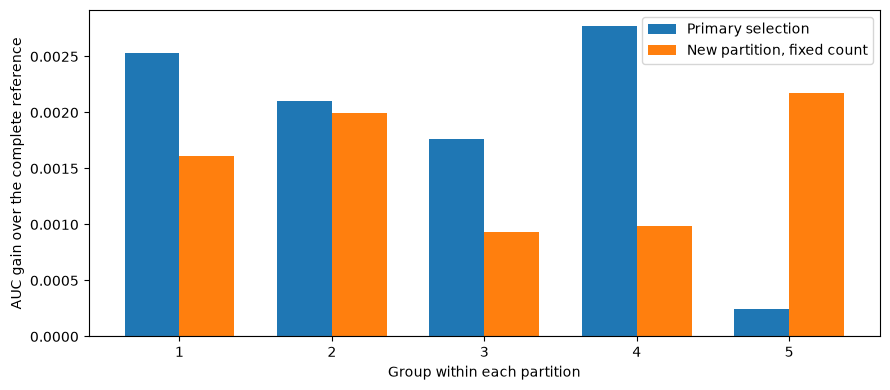

In [5]:
freeze=read(ART/'model_selection_freeze.json')
for name,want in freeze['hashes'].items():
    assert hashlib.sha256((HERE/name).read_bytes()).hexdigest()==want,name
choice=read(ART/'model_selection.json');confirm=read(ART/'model_confirmation.json');average=read(ART/'model_averaging.json')
display(pd.Series(choice));display(pd.Series(confirm));display(pd.Series(average))
display(pd.DataFrame(read(ART/'model_blend_grid.json')).head(15))
if 'fold_gains'in confirm:
    fig,ax=plt.subplots(figsize=(9,4));xx=np.arange(1,6)
    ax.bar(xx-.18,choice['fold_gains'],.36,label='Primary selection')
    ax.bar(xx+.18,confirm['fold_gains'],.36,label='New partition, fixed count')
    ax.axhline(0,color='gray',linewidth=.8);ax.set(xlabel='Group within each partition',ylabel='AUC gain over the complete reference')
    ax.legend();fig.tight_layout();fig.savefig(ART/'model_fold_gains.png',dpi=140);plt.show()

## Recommended CSV and saved-model replay

A newly accepted file is replayed below through the same project-venv CLI
that sets one OpenMP runtime. No duplicate-runtime checks are disabled. A
retained reference is checked against its preserved checksum and prior exact
replay evidence. A model's own training AUC and this notebook's local scores
are not public scores. Full-data OOF never retunes the chosen recipe.

In [6]:
if final['accepted']:
    subprocess.run([sys.executable,str(HERE/'h_launch.py'),'reproduce'],check=True,cwd=ROOT)
replay=read(ART/'model_reproduction.json');assert replay['byte_identical']
path=ROOT/final['submission'];assert hashlib.sha256(path.read_bytes()).hexdigest()==final['sha256']==replay['sha256']
sub=pd.read_csv(path);sample=pd.read_csv(ROOT/'input/sample_submission.csv');test=pd.read_csv(ROOT/'input/test.csv')
assert list(sub)==['SK_ID_CURR','TARGET'] and len(sub)==61500
assert sub.SK_ID_CURR.equals(sample.SK_ID_CURR) and sub.SK_ID_CURR.equals(test.SK_ID_CURR)
assert sub.SK_ID_CURR.is_unique and np.isfinite(sub.TARGET).all() and sub.TARGET.between(0,1).all()
print('Recommended CSV:',final['submission']);display(replay);display(sub.head())
protected=read(HERE/'reference/modeling_preserved_hashes.json');checked=0
for name,want in protected.items():
    path=ROOT/name
    if path.exists():
        assert hashlib.sha256(path.read_bytes()).hexdigest()==want,name
        checked+=1
print('Unchanged protected files present:',checked)

EXACT REPLAY 15d050aa8709ae4e2d338b013c03216d4b3f3279348a3faca71080c17e44baed


Recommended CSV: output/submission_high_upside.csv


{'byte_identical': True,
 'sha256': '15d050aa8709ae4e2d338b013c03216d4b3f3279348a3faca71080c17e44baed',
 'path': 'output/submission_high_upside_reproduced.csv',
 'saved_model_replay': True}

,SK_ID_CURR,TARGET
0,171202,0.026094
1,171203,0.204231
2,171204,0.171741
3,171205,0.104670
4,171206,0.190041


Unchanged protected files present: 231


## Deliberate rerun

Saved evidence is displayed by default. Training below is opt-in and matching
exact signatures reuse caches. The current journal describes all negatives,
operations and limitations. The next research direction must earn its cost;
finishing these recipes does not prove all possible improvements exhausted.

In [7]:
RUN_MODEL_PIPELINE=False
if RUN_MODEL_PIPELINE:
    subprocess.run([sys.executable,str(HERE/'h_launch.py'),'run'],check=True,cwd=ROOT)
display(Markdown((ROOT/'HIGH_UPSIDE_EXPERIMENT_LOG.md').read_text()))

# Higher-upside research journal

## Leaderboard context and target

The user reports that the top ten entries display scores of 1 and the top twenty
are above 0.8, while explicitly expressing uncertainty about external-data use.
This observation is recorded in `improvements/high_upside/artifacts/leaderboard_context.json`.
Methods, compliance and private-test performance were not independently verified.
No allegation about other participants is made. The competitive target is **0.8+**;
its attainability using the permitted inputs remains unproven.

## H1: attribute ranking errors before selecting expensive branches

**Why:** The user redirected effort away from incremental tuning. A weak AUC on a
small slice is insufficient evidence that a specialist can materially improve the
whole submission. Attribute errors to the population and pair types they affect.

**How:** Use the frozen round-three three-seed development OOF predictions on
136,961 rows. Compute reversed positive-negative pairs, assigning half-error to
ties. Decompose global `1 - AUC` by positive-group and negative-group membership
for loan contract, income, education, gender, external-score missing count and
pattern, and age band. Verify each matrix sums back to the exact global loss.
Also compare one saved CatBoost model's predictions on a deterministic sample of
20,000 own-training rows with its cached predictions on 34,241 held-out rows.
There is no new fit, model selection or adjustment of predictions in this audit.

**Observed:**

- Complete three-seed development OOF AUC: **0.7648034855**. This is a local
  diagnostic, distinct from the confirmed submitted public score **0.76824**.
- The group missing two external scores has 30,767 rows, 2,791 positives and
  within-group AUC **0.743954**. Its share of positive-centered global ranking
  loss is **23.09%**, compared with **25.24%** of all positive applicants. Lower
  within-group AUC did not identify disproportionate global error contribution.
- **85.26%** of total ranking loss occurs within contract-type groups; cash-loan
  rows account for most of this because they dominate the population. There is
  no obvious tiny contract segment whose correction alone explains a large jump.
- The saved model's own-training sample AUC is **0.8140925** versus held-out AUC
  **0.7651793**. This shows an in-sample/held-out gap for that fit. It does not
  measure the attainable ceiling or isolate why generalization fails.
- Mean calibration residuals for the large missing-count and contract groups are
  small. Global monotone probability calibration would preserve score order and
  cannot increase AUC. Learned interactions may still change relative rankings.

**Decision and reasoning:** Prioritize a different generalization strategy and
learned representation across the population. Simple depth increases, arbitrary
missing-score specialists, hand adjustments and additional seed banks are not
justified by these descriptive results. The first neural pilot should compare a
scratch TabM with numerical embeddings on raw and successful engineered features.
Selected borrower/profile interactions can be tested against the same fixed tree
learner. Missing-score reconstruction remains conditional on auxiliary OOF quality
and downstream ranking gains; observed-score masking may not represent the true
missing population. Retrieval and fully nested stacking require evidence first.
No claim is made that any proposed branch will achieve 0.8.

**Evidence:**

- New notebook: `07_signal_opportunity_audit.ipynb`.
- Recorded audit plan and source: `improvements/high_upside/OPPORTUNITY_AUDIT_PLAN.md`
  and `opportunity_audit.py` in the same directory.
- `artifacts/audit_summary.json`: source, data, split and prediction hashes;
  local-venv provenance and capacity diagnostic.
- `artifacts/pair_loss_cells.csv`, `group_slices.csv`, `within_between_loss.csv`:
  complete numerical results, including sparse groups.
- `artifacts/external_score_pair_loss.png`: pair matrix and group-size comparison.

**Limits:** All development labels have been explored previously. This is a
hypothesis-generation audit, not independent confirmation or a measured upper
bound. Pair-loss cells are descriptive quantities, not automatically attainable
improvements. Group comparisons can reflect differences in case mix.

**Operational correction:** The first execution of the new draft notebook used
`slices.sparse` to access a column, which collided with pandas' sparse-data accessor.
It was corrected to bracket access and the new notebook was rerun. The failed
execution snapshot is preserved under `improvements/high_upside/reference`.
Previously existing notebooks were unchanged. No model or data changed because
of this presentation error. Plot annotation contrast was also improved.

## Status when the opportunity audit concluded

The revised strategy is in `HIGH_UPSIDE_PLAN.md`. Exact neural pilot settings,
runtime/memory limits and promotion gates must be recorded before model fitting.
PyTorch was not installed at the time of this audit. No neural pilot has yet run,
and no new submission has been produced. Current recommendation remains the
public-confirmed round-three bagged CSV. The old round-four controller remains
stopped; its seven completed screens remain documented separately.


## Model-stage recorded plan

# Higher-upside model pilots and submission gates

Recorded before fitting these candidates. The user has authorized continuing
through training, validation and a submission decision. The prior incremental
round-four controller stays stopped. Current reference is the public-confirmed
round-three bagged CSV (0.76824). No external rows or pretrained weights.

## Six structural pilots

Four scratch TabM recipes: raw inputs with piecewise-linear numerical embeddings;
the successful signed 55-column frame with the same recipe; that frame with
periodic numerical embeddings; and a more regularized full TabM recipe. The first
three use the efficient mini architecture. Common settings: 16 internal members,
128 hidden units, two blocks, eight-dimensional embeddings, AdamW, batch 1,024,
cosine learning-rate schedule, up to 140 epochs, 20-epoch AUC patience. Regularized
recipe uses 180 epochs, learning rate .001 versus .002, dropout .25 versus .10,
and weight decay .003 versus .0003. These are combined recipes; that comparison
does not identify a single parameter effect. Numerical medians/quantile transforms,
category vocabularies, nonconstant column selection and embedding bins fit training
rows only. Explicit numerical missing flags are included. Unknown categories get
a reserved category. Each member's BCE is optimized independently; inference
averages probabilities, as the authors specify.

Two CatBoost pilots hold the successful family settings (depth5, l2=8,
random_strength=.5, learning_rate=.045, max4,500 trees, patience200) fixed:

1. Add three fold-safe reconstructed external scores and observed-score residuals.
   Auxiliary LightGBM regressors use only supplied feature columns, exclude their
   predicted score column and TARGET/ID, and train on observed auxiliary targets.
   Training-row reconstructions are three-fold OOF; validation/test reconstructions
   use regressors fitted only on the outer training rows. Missingness is retained.
   Save auxiliary OOF R2 on observed rows; positive auxiliary R2 is not sufficient
   for acceptance and may not transfer to truly missing cases.
2. Add smoothed cross-fitted risk encodings for predeclared borrower/loan/score
   interactions. Five inner folds generate training encodings; full outer-train
   maps encode validation/test. Two prior strengths (30,100) and support/frequency
   features are a block, not individually selected. Outer validation labels are
   absent from every map and every fit. Cut edges fit only outer training inputs.

Exact specs are written to `artifacts/model_candidate_plan.json` before fitting.
No source edits to the fitting core while any fit process is running. Include
actual source/data/split/package hashes in cache identities. Neural processes use
one OpenMP library via DYLD_LIBRARY_PATH on this Mac; do not suppress duplicate
runtime detection with KMP_DUPLICATE_LIB_OK. Hardware currently exposes CPU only.
Save learning curves, timings, seeds, versions, failures and full predictions.

## Compute allocation and progression

Use the original repeatedly explored inner split to screen all six. Limit each
neural pilot to 25 minutes; stop at the best completed epoch if reached and label
the truncation. This is not a negative claim about an unconverged model. Run neural
models sequentially with four CPU threads. Fit no more than two finalists in
primary common-five-fold development CV: best neural and best learned-feature
CatBoost, each needing >=0.00030 screened blend gain over the entire reference.
Probe new-family weights .10,.25,.50,.75,1.00. If a neural model is truncated before
15 epochs without a useful gain, do not expand it. No random broad sweep.

For the finalists, compare on the original primary five folds (SEED+2). Search a
complete primary-only grid: reference/new and new/new pairs with weights
.10,.25,1/3,.50,2/3,.75,.90; and reference plus both helpers with reference weights
.25,.50,.75 and relative helper shares .25,.50,.75. Probability and log-odds means
only. Freeze the complete winner and fixed median epochs/iterations before any
confirmation. At most two new families.

The ambition for a substantial branch is >=0.002 OOF gain; a smaller robust gain
can still justify a candidate, but will not trigger a bigger sweep or seed bank.
Require >=0.00030 primary gain for submission eligibility. Confirmation uses
SEED+3101 (not any earlier confirmation seed), fixed counts, no validation early
stopping, frozen weights/method, positive pooled gain and >=4/5 positive groups.
Fit matching new-family OOF on the two other existing development seeds
(SEED+301,SEED+1101). Average each family before the frozen blend; require >=0.00030
gain over the complete three-seed reference plus >=4/5 positive primary groups.
These are explored development labels; new partitions are robustness checks,
not an untouched test. Public feedback does not select weights.

If no pilot reaches promotion, complete the negative-result journal and retain
the existing submission; do not create a deceptively relabeled CSV. If a family
fails a later gate, retain its evidence and stop its deployment branch.

## Submission and delivery

A passing recipe reuses the original bank and trains only needed new families on
three full-data five-fold seeds (SEED+3,+302,+602), frozen lengths, with no use of
held-out labels for stopping. Write `output/submission_high_upside.csv`; preserve
all previous CSVs. Reproduce from saved models byte-for-byte, check all61,500 IDs,
schema, finiteness and score range. Full-data OOF is diagnostic and does not retune.
Document the exact score provenance and avoid claiming 0.8 without an actual
submitted score. Create new notebooks only; execute them with the local venv.
Update the report/journal and create a new verified reproduction archive if a new
submission is accepted. Even a failed branch gets executed result documentation.

## References

Methods/code only: https://github.com/yandex-research/tabm and its documented
numerical-embedding dependency. Installed package licenses/versions are recorded.
No repository datasets, pretrained models, original Home Credit tables or labels
are imported. These method references do not predict a gain on this competition.


## Prospective local-GPU amendment

# Prospective local-GPU amendment

Timing: after the first three CPU pilots completed, before the regularized neural
pilot completed and before any primary CV, recipe selection or confirmation.
No score gate, candidate hyperparameter or weight grid changes.

The sandbox reported MPS unavailable. A separate local hardware check outside the
sandbox reported MPS available. A randomly initialized representative network
measured 0.10265 seconds/batch on CPU and 0.03308 on MPS, approximately three times
faster. This is a throughput probe, not a competitive model or dataset.
`artifacts/model_neural_hardware_check.json` records the result.

The CPU worker and waiting delivery worker were stopped. The first three complete
CPU model/prediction/curve/metric artifacts remain byte-identical; their hashes,
specs, original identity and reuse reason are recorded in
`reference/cpu_stage_reuse.json`. The interrupted regularized model has no final
pilot record and is not counted as a scientific negative. Its partial learning
curve and the original runner/logs are preserved under `reference/cpu_stage`.

New `h_accel.py` trains subsequent neural fits on the local MPS GPU. It reuses the
unchanged encoder, feature functions and predictor classes from the original
fitting core. Initial weights and shuffle order are seeded on CPU, with MPS seeded
too. Architecture, losses, optimizer, learning-rate schedule, stopping budgets and
validation gates remain those in the original plan. Trees and preprocessing remain
on CPU. GPU validation can have small float32 differences; retained predictions
and all saved-model inference are generated on CPU. Exact saved-weight replay on
CPU is checked; bit-identical GPU retraining is not promised.

The current engine identity includes the separately hashed GPU implementation and
this amendment. Historical CPU pilot results retain their original signatures.
They are reused only as recorded stage evidence after checking their complete
artifact hashes, exact specs, unchanged original core/data/package identity and
explicit CPU diagnostics. They are not silently relabeled as GPU results or
asserted to equal a new GPU fit. All new CV/final results use the new identity.

This mixed-hardware pilot stage compares complete recipes. It does not isolate
architecture or regularization effects from hardware numerical differences.
All newly selected families are validated on the same current backend through
the unchanged downstream gates. Source/recipe freezes still precede confirmation.
No outside data, cloud resources, pretrained weights or transfers are involved.


## Budget-aware selection before freeze

# Budget-aware recipe selection, before freeze and confirmation

Timing: the neural primary CV and a read-only neural/reference pair preview were
complete; tree primary CV was still running. The complete joint grid, selected
recipe and any confirmation results had not been observed. Both workers were
stopped before changing the selection controller. The original runner/log/state
are preserved under `reference/before_complexity_policy`. Completed fits remain
unchanged, and no fitting source, hyperparameter, data or cached prediction changes.

The user explicitly prioritized larger steps over spending time on negligible
improvements. Apply this additional compute-allocation rule to the already-declared
primary grid: a recipe using two new families must gain **at least 0.00030 AUC**
over the best recipe using at most one new family. Otherwise choose the best
one-family addition. The reference alone is eligible as the simpler candidate.
The rule controls future training cost; it is not a significance test.

Keep the entire unconstrained grid, its maximum, the simpler maximum and the
incremental contribution in the selection record. Do not erase a more complex
candidate's score or the tree finalist's CV. Existing overall >=0.00030 eligibility,
fresh confirmation and matching-three-seed gates remain unchanged. No new methods,
weights or family configurations are introduced. The chosen recipe is frozen
before any confirmation; no simplification or reweighting occurs afterwards.

Fit cache identities stay unchanged because fitting code/inputs are unchanged.
The selection freeze additionally hashes this policy and amended controller.
Cold reproduction therefore applies the same explicit budget-aware rule.
This amendment is an adaptive budget decision with its timing recorded, rather
than presented as part of the original pre-pilot plan.


## Every pilot

| Pilot | Status | Individual inner AUC | Best blend gain | Retained count | Seconds |
| --- | --- | --- | --- | --- | --- |
| hu_tabm_raw_piecewise | complete | 0.7401112070113721 | 0.00023940711171865914 | 28 | 278.6 |
| hu_tabm_signed_piecewise | complete | 0.7508051844254278 | 0.0015386237266847846 | 30 | 366.8 |
| hu_tabm_signed_periodic | complete | 0.7481981652282162 | 0.0009184341384127492 | 37 | 442.0 |
| hu_tabm_regularized | complete | 0.7501469096931409 | 0.0009786278608223675 | 37 | 263.1 |
| hu_cat_score_reconstruction | complete | 0.7507565995744394 | 0.0003658748466190964 | 1217 | 112.7 |
| hu_cat_interaction_risk | complete | 0.745379657680358 | -0.00013253653104949858 | 991 | 99.3 |

### hu_tabm_raw_piecewise

Numerical embeddings and joint shared-weight ensembling on supplied raw predictors.

Standalone inner AUC 0.7401112; best blend gain +0.0002394 against the complete current reference. Did not advance under the recorded promotion rule. Retained epoch 28 of 48 completed; stopping reason: AUC patience. This tests this embedding/shared-ensemble recipe, not all neural architectures. A time-truncated fit cannot rule out useful convergence. Mechanisms are hypotheses, not causal findings. Repeatedly explored selection labels cannot establish hidden-test improvement.

```json
{
  "kind": "tabm",
  "architecture": "tabm-mini",
  "dropout": 0.1,
  "learning_rate": 0.002,
  "weight_decay": 0.0003,
  "max_epochs": 140,
  "patience": 20,
  "max_seconds": 1500,
  "name": "hu_tabm_raw_piecewise",
  "features": "raw",
  "embedding": "piecewise",
  "hypothesis": "Numerical embeddings and joint shared-weight ensembling on supplied raw predictors."
}
```

Raw metrics/all five weights: [improvements/high_upside/artifacts/pilots/hu_tabm_raw_piecewise.json](improvements/high_upside/artifacts/pilots/hu_tabm_raw_piecewise.json). Full curves and predictions are adjacent.

```json
{
  "stop_reason": "AUC patience",
  "epochs_completed": 48,
  "parameters": 88032,
  "numeric_dimensions": 34,
  "categorical_cardinalities": [
    3,
    4,
    9,
    6,
    7,
    7,
    20,
    59
  ],
  "device": "cpu",
  "source_hashes": {
    "h_models.py": "ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461",
    "h_features.py": "47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42"
  }
}
```

### hu_tabm_signed_piecewise

Same neural recipe with the successful tree representation.

Standalone inner AUC 0.7508052; best blend gain +0.0015386 against the complete current reference. Promoted to common-fold CV. Retained epoch 30 of 50 completed; stopping reason: AUC patience. This tests this embedding/shared-ensemble recipe, not all neural architectures. A time-truncated fit cannot rule out useful convergence. Mechanisms are hypotheses, not causal findings. Repeatedly explored selection labels cannot establish hidden-test improvement.

```json
{
  "kind": "tabm",
  "architecture": "tabm-mini",
  "dropout": 0.1,
  "learning_rate": 0.002,
  "weight_decay": 0.0003,
  "max_epochs": 140,
  "patience": 20,
  "max_seconds": 1500,
  "name": "hu_tabm_signed_piecewise",
  "features": "signed",
  "embedding": "piecewise",
  "hypothesis": "Same neural recipe with the successful tree representation."
}
```

Raw metrics/all five weights: [improvements/high_upside/artifacts/pilots/hu_tabm_signed_piecewise.json](improvements/high_upside/artifacts/pilots/hu_tabm_signed_piecewise.json). Full curves and predictions are adjacent.

```json
{
  "stop_reason": "AUC patience",
  "epochs_completed": 50,
  "parameters": 136608,
  "numeric_dimensions": 64,
  "categorical_cardinalities": [
    3,
    4,
    9,
    6,
    7,
    7,
    20,
    59,
    9,
    5
  ],
  "device": "cpu",
  "source_hashes": {
    "h_models.py": "ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461",
    "h_features.py": "47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42"
  }
}
```

Primary common-fold CV:
```json
{
  "name": "hu_tabm_signed_piecewise",
  "origin": "high_upside",
  "auc": 0.7606961995750414,
  "average_precision": 0.24528499793703737,
  "log_loss": 0.247457830829399,
  "brier": 0.06789587893829382,
  "counts": [
    29,
    32,
    40,
    40,
    41
  ],
  "fold_auc": [
    0.7592338701077257,
    0.7663843757626265,
    0.7617888190091704,
    0.7620385083187231,
    0.7647530905868344
  ],
  "fold_seconds": [
    222.4787528514862,
    237.2306890487671,
    270.1254358291626,
    258.7743191719055,
    269.8758490085602
  ],
  "seconds": 1258.5929939746857
}
```

### hu_tabm_signed_periodic

Periodic numerical embeddings can expose different smooth thresholds and interactions.

Standalone inner AUC 0.7481982; best blend gain +0.0009184 against the complete current reference. Did not advance under the recorded promotion rule. Retained epoch 37 of 57 completed; stopping reason: AUC patience. This tests this embedding/shared-ensemble recipe, not all neural architectures. A time-truncated fit cannot rule out useful convergence. Mechanisms are hypotheses, not causal findings. Repeatedly explored selection labels cannot establish hidden-test improvement.

```json
{
  "kind": "tabm",
  "architecture": "tabm-mini",
  "dropout": 0.1,
  "learning_rate": 0.002,
  "weight_decay": 0.0003,
  "max_epochs": 140,
  "patience": 20,
  "max_seconds": 1500,
  "name": "hu_tabm_signed_periodic",
  "features": "signed",
  "embedding": "periodic",
  "hypothesis": "Periodic numerical embeddings can expose different smooth thresholds and interactions."
}
```

Raw metrics/all five weights: [improvements/high_upside/artifacts/pilots/hu_tabm_signed_periodic.json](improvements/high_upside/artifacts/pilots/hu_tabm_signed_periodic.json). Full curves and predictions are adjacent.

```json
{
  "stop_reason": "AUC patience",
  "epochs_completed": 57,
  "parameters": 112296,
  "numeric_dimensions": 64,
  "categorical_cardinalities": [
    3,
    4,
    9,
    6,
    7,
    7,
    20,
    59,
    9,
    5
  ],
  "device": "cpu",
  "source_hashes": {
    "h_models.py": "ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461",
    "h_features.py": "47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42"
  }
}
```

### hu_tabm_regularized

A full TabM recipe with stronger regularization tests a different generalization tradeoff; several settings change jointly.

Standalone inner AUC 0.7501469; best blend gain +0.0009786 against the complete current reference. Did not advance under the recorded promotion rule. Retained epoch 37 of 57 completed; stopping reason: AUC patience. This tests this embedding/shared-ensemble recipe, not all neural architectures. A time-truncated fit cannot rule out useful convergence. Mechanisms are hypotheses, not causal findings. Repeatedly explored selection labels cannot establish hidden-test improvement.

```json
{
  "kind": "tabm",
  "architecture": "tabm",
  "dropout": 0.25,
  "learning_rate": 0.001,
  "weight_decay": 0.003,
  "max_epochs": 180,
  "patience": 20,
  "max_seconds": 1500,
  "name": "hu_tabm_regularized",
  "features": "signed",
  "embedding": "piecewise",
  "hypothesis": "A full TabM recipe with stronger regularization tests a different generalization tradeoff; several settings change jointly."
}
```

Raw metrics/all five weights: [improvements/high_upside/artifacts/pilots/hu_tabm_regularized.json](improvements/high_upside/artifacts/pilots/hu_tabm_regularized.json). Full curves and predictions are adjacent.

```json
{
  "stop_reason": "AUC patience",
  "epochs_completed": 57,
  "parameters": 146592,
  "numeric_dimensions": 64,
  "categorical_cardinalities": [
    3,
    4,
    9,
    6,
    7,
    7,
    20,
    59,
    9,
    5
  ],
  "device": "mps",
  "inference_device": "cpu",
  "gpu_cpu_prediction_max_difference": 1.1920928955078125e-07,
  "gpu_source_sha256": "660ecd8d5ac2ea523785f3b70e36f91af35885774ce1f724c9ded5d983c42c1e",
  "source_hashes": {
    "h_models.py": "ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461",
    "h_features.py": "47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42"
  },
  "retraining_bitwise_determinism_promised": false
}
```

### hu_cat_score_reconstruction

Use observed external scores as auxiliary supervised targets, with nested OOF reconstructions and residuals.

Standalone inner AUC 0.7507566; best blend gain +0.0003659 against the complete current reference. Promoted to common-fold CV. Auxiliary score R2 measures reconstruction on observed rows, not default ranking or quality on genuinely missing scores. Downstream validation determines usefulness. Mechanisms are hypotheses, not causal findings. Repeatedly explored selection labels cannot establish hidden-test improvement.

```json
{
  "name": "hu_cat_score_reconstruction",
  "kind": "cat",
  "features": "signed",
  "learned": "score_reconstruction",
  "params": {
    "depth": 5,
    "l2_leaf_reg": 8,
    "random_strength": 0.5
  },
  "max_iterations": 4500,
  "patience": 200,
  "hypothesis": "Use observed external scores as auxiliary supervised targets, with nested OOF reconstructions and residuals."
}
```

Raw metrics/all five weights: [improvements/high_upside/artifacts/pilots/hu_cat_score_reconstruction.json](improvements/high_upside/artifacts/pilots/hu_cat_score_reconstruction.json). Full curves and predictions are adjacent.

```json
{
  "auxiliary": {
    "EXT_SOURCE_1": {
      "observed_rows": 31323,
      "auxiliary_oof_r2": 0.48281908293018505
    },
    "EXT_SOURCE_2": {
      "observed_rows": 102499,
      "auxiliary_oof_r2": 0.23558830463737035
    },
    "EXT_SOURCE_3": {
      "observed_rows": 70019,
      "auxiliary_oof_r2": 0.11573969267290851
    }
  },
  "source_hashes": {
    "h_models.py": "ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461",
    "h_features.py": "47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42"
  }
}
```

Primary common-fold CV:
```json
{
  "name": "hu_cat_score_reconstruction",
  "origin": "high_upside",
  "auc": 0.7630882410204641,
  "average_precision": 0.24416624931520592,
  "log_loss": 0.24496733692589584,
  "brier": 0.06770824427366888,
  "counts": [
    1166,
    848,
    1150,
    1537,
    1085
  ],
  "fold_auc": [
    0.758352834699201,
    0.7655283661263057,
    0.7635091723349453,
    0.7634574796519332,
    0.7646987620416904
  ],
  "fold_seconds": [
    141.04638814926147,
    111.32487416267395,
    138.21902513504028,
    176.69305109977722,
    100.68420219421387
  ],
  "seconds": 100.7748441696167
}
```

### hu_cat_interaction_risk

Use regularized OOF borrower/loan/score interaction risks to expose nonlinear population structure.

Standalone inner AUC 0.7453797; best blend gain -0.0001325 against the complete current reference. Did not advance under the recorded promotion rule. Inner OOF risk maps prevent direct own-target encoding; their extra supervised representation can still add noise, selection bias or redundant signal already available to CatBoost. Mechanisms are hypotheses, not causal findings. Repeatedly explored selection labels cannot establish hidden-test improvement.

```json
{
  "name": "hu_cat_interaction_risk",
  "kind": "cat",
  "features": "signed",
  "learned": "interaction_risk",
  "params": {
    "depth": 5,
    "l2_leaf_reg": 8,
    "random_strength": 0.5
  },
  "max_iterations": 4500,
  "patience": 200,
  "hypothesis": "Use regularized OOF borrower/loan/score interaction risks to expose nonlinear population structure."
}
```

Raw metrics/all five weights: [improvements/high_upside/artifacts/pilots/hu_cat_interaction_risk.json](improvements/high_upside/artifacts/pilots/hu_cat_interaction_risk.json). Full curves and predictions are adjacent.

```json
{
  "auxiliary": {
    "inner_folds": 5,
    "interactions": 8,
    "features": 32
  },
  "source_hashes": {
    "h_models.py": "ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461",
    "h_features.py": "47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42"
  }
}
```

## Software and leakage checks

```json
{
  "passed": true,
  "signature": "fd4bd07beac5036482fe45fa854ed47d1e981739c35a88e7d7ea98a32153eb42",
  "feature_target_id_independence": true,
  "train_test_schema": true,
  "neural_saved_model_replay_exact": true,
  "neural_batch_max_difference": 2.9802322387695312e-08,
  "unknown_category_reserved": true,
  "learned_transform_batch_invariance": true,
  "auxiliary_software_probe": {
    "score_reconstruction": {
      "EXT_SOURCE_1": {
        "observed_rows": 341,
        "auxiliary_oof_r2": 0.25237476992076346
      },
      "EXT_SOURCE_2": {
        "observed_rows": 1198,
        "auxiliary_oof_r2": 0.09835271965101033
      },
      "EXT_SOURCE_3": {
        "observed_rows": 803,
        "auxiliary_oof_r2": -0.023918244457870053
      }
    },
    "interaction_risk": {
      "inner_folds": 5,
      "interactions": 8,
      "features": 32
    }
  },
  "prior_75_model_replay_max_difference": 1.1102230246251565e-16,
  "python": "/Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python",
  "training_backend": "mps",
  "inference_backend": "cpu",
  "gpu_cpu_prediction_max_difference": 8.940696716308594e-08,
  "note": "Tiny two-epoch neural fit and small auxiliary fits are software checks, not competitive trial results."
}
```

## Exact environment

```json
{
  "identity": {
    "sources": {
      "h_models.py": "ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461",
      "h_features.py": "47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42"
    },
    "dependencies": "d0aec5be64502e2221948604668af1cef86b6c63a68bf6bd3f34ea4ddf7a8bc0",
    "packages": {
      "numpy": "2.5.4",
      "pandas": "3.0.6",
      "scikit-learn": "1.9.1",
      "catboost": "1.2.10",
      "lightgbm": "4.7.0",
      "torch": "2.15.0",
      "tabm": "0.0.3",
      "rtdl_num_embeddings": "0.0.12",
      "joblib": "1.6.0"
    },
    "plan_sha256": "895201103c1193357228009c6d4b670b932bce6c87cbed6314028ee5d6476452",
    "gpu_source_sha256": "660ecd8d5ac2ea523785f3b70e36f91af35885774ce1f724c9ded5d983c42c1e",
    "training_backend": "mps",
    "accelerator_amendment_sha256": "1fbf383c17ab2ee9bcd3bc635818fb48b058c719d22ee8168b0aa2a080bfddf8"
  },
  "signature": "fd4bd07beac5036482fe45fa854ed47d1e981739c35a88e7d7ea98a32153eb42",
  "python": "/Volumes/Projects/GCI World_202609/04. Competition (due XX)/Competition/.venv/bin/python",
  "training_device": "mps",
  "inference_device": "cpu",
  "threads": 4,
  "original_cpu_identity": {
    "sources": {
      "h_models.py": "ce6f6bf04d2058623aa5bc95dde6a8be030ce6f91d390c029e03182486363461",
      "h_features.py": "47837f88af209e04af23c0babfeb89bb27be700a646623b04701fdd844420b42"
    },
    "dependencies": "d0aec5be64502e2221948604668af1cef86b6c63a68bf6bd3f34ea4ddf7a8bc0",
    "packages": {
      "numpy": "2.5.4",
      "pandas": "3.0.6",
      "scikit-learn": "1.9.1",
      "catboost": "1.2.10",
      "lightgbm": "4.7.0",
      "torch": "2.15.0",
      "tabm": "0.0.3",
      "rtdl_num_embeddings": "0.0.12",
      "joblib": "1.6.0"
    },
    "plan_sha256": "895201103c1193357228009c6d4b670b932bce6c87cbed6314028ee5d6476452"
  },
  "original_cpu_signature": "97df13e32b1d82c9b150abaf948f529c20f27b43bac158c852a86c3ee6a7fb84",
  "cpu_stage_reuse_proof": "reference/cpu_stage_reuse.json"
}
```

## Promotion

```json
{
  "chosen": [
    {
      "name": "hu_tabm_signed_piecewise",
      "spec": {
        "kind": "tabm",
        "architecture": "tabm-mini",
        "dropout": 0.1,
        "learning_rate": 0.002,
        "weight_decay": 0.0003,
        "max_epochs": 140,
        "patience": 20,
        "max_seconds": 1500,
        "name": "hu_tabm_signed_piecewise",
        "features": "signed",
        "embedding": "piecewise",
        "hypothesis": "Same neural recipe with the successful tree representation."
      },
      "origin": "high_upside"
    },
    {
      "name": "hu_cat_score_reconstruction",
      "spec": {
        "name": "hu_cat_score_reconstruction",
        "kind": "cat",
        "features": "signed",
        "learned": "score_reconstruction",
        "params": {
          "depth": 5,
          "l2_leaf_reg": 8,
          "random_strength": 0.5
        },
        "max_iterations": 4500,
        "patience": 200,
        "hypothesis": "Use observed external scores as auxiliary supervised targets, with nested OOF reconstructions and residuals."
      },
      "origin": "high_upside"
    }
  ],
  "threshold": 0.0003,
  "decisions": [
    {
      "name": "hu_tabm_raw_piecewise",
      "status": "complete",
      "promoted": false,
      "gain": 0.00023940711171865914
    },
    {
      "name": "hu_tabm_signed_piecewise",
      "status": "complete",
      "promoted": true,
      "gain": 0.0015386237266847846
    },
    {
      "name": "hu_tabm_signed_periodic",
      "status": "complete",
      "promoted": false,
      "gain": 0.0009184341384127492
    },
    {
      "name": "hu_tabm_regularized",
      "status": "complete",
      "promoted": false,
      "gain": 0.0009786278608223675
    },
    {
      "name": "hu_cat_score_reconstruction",
      "status": "complete",
      "promoted": true,
      "gain": 0.0003658748466190964
    },
    {
      "name": "hu_cat_interaction_risk",
      "status": "complete",
      "promoted": false,
      "gain": -0.00013253653104949858
    }
  ]
}
```

## Primary frozen selection

```json
{
  "names": [
    "round3_reference",
    "hu_tabm_signed_piecewise",
    "hu_cat_score_reconstruction"
  ],
  "weights": [
    0.25,
    0.375,
    0.375
  ],
  "method": "probability",
  "auc": 0.7654305267165775,
  "baseline_auc": 0.7637228893732684,
  "gain": 0.001707637343309143,
  "primary_gate_passed": true,
  "substantial_gain": false,
  "fold_gains": [
    0.0025327478961900685,
    0.0021043124935127278,
    0.0017645022537956523,
    0.0027759581462415417,
    0.00024191104338100455
  ],
  "new_families": [
    {
      "name": "hu_tabm_signed_piecewise",
      "spec": {
        "kind": "tabm",
        "architecture": "tabm-mini",
        "dropout": 0.1,
        "learning_rate": 0.002,
        "weight_decay": 0.0003,
        "max_epochs": 140,
        "patience": 20,
        "max_seconds": 1500,
        "name": "hu_tabm_signed_piecewise",
        "features": "signed",
        "embedding": "piecewise",
        "hypothesis": "Same neural recipe with the successful tree representation."
      },
      "origin": "high_upside",
      "counts": [
        29,
        32,
        40,
        40,
        41
      ],
      "fixed_count": 40
    },
    {
      "name": "hu_cat_score_reconstruction",
      "spec": {
        "name": "hu_cat_score_reconstruction",
        "kind": "cat",
        "features": "signed",
        "learned": "score_reconstruction",
        "params": {
          "depth": 5,
          "l2_leaf_reg": 8,
          "random_strength": 0.5
        },
        "max_iterations": 4500,
        "patience": 200,
        "hypothesis": "Use observed external scores as auxiliary supervised targets, with nested OOF reconstructions and residuals."
      },
      "origin": "high_upside",
      "counts": [
        1166,
        848,
        1150,
        1537,
        1085
      ],
      "fixed_count": 1150
    }
  ],
  "confirmation_seed": 20264209,
  "grid_size": 61,
  "best_attempt": {
    "names": [
      "round3_reference",
      "hu_tabm_signed_piecewise",
      "hu_cat_score_reconstruction"
    ],
    "weights": [
      0.25,
      0.375,
      0.375
    ],
    "method": "probability",
    "auc": 0.7654305267165775
  },
  "complexity_policy": "COMPLEXITY_POLICY.md",
  "budget_policy_applied": false,
  "unconstrained_best": {
    "names": [
      "round3_reference",
      "hu_tabm_signed_piecewise",
      "hu_cat_score_reconstruction"
    ],
    "weights": [
      0.25,
      0.375,
      0.375
    ],
    "method": "probability",
    "auc": 0.7654305267165775
  },
  "best_at_most_one_new_family": {
    "names": [
      "round3_reference",
      "hu_tabm_signed_piecewise"
    ],
    "weights": [
      0.6666666666666666,
      0.33333333333333337
    ],
    "method": "probability",
    "auc": 0.7650343253899636
  },
  "second_family_increment": 0.0003962013266138875,
  "minimum_increment_for_second_family": 0.0003
}
```

## Confirmation

```json
{
  "baseline": {
    "auc": 0.7627263204899741,
    "average_precision": 0.24775138426099164,
    "log_loss": 0.2447785588143546,
    "brier": 0.06758934274011608
  },
  "candidate": {
    "auc": 0.7642283520726878,
    "average_precision": 0.24943991449967523,
    "log_loss": 0.2443028793338643,
    "brier": 0.06749568766964958
  },
  "gain": 0.0015020315827136699,
  "fold_gains": [
    0.001609001821388234,
    0.0019942993998888214,
    0.0009308454819668688,
    0.000983059043299872,
    0.002170197363790871
  ],
  "positive_folds": 5,
  "passed": true,
  "weights_retuned": false,
  "validation_early_stopping": false,
  "caveat": "Fresh partition of repeatedly explored labels; not an untouched test."
}
```

## Matching three-seed comparison

```json
{
  "baseline": {
    "auc": 0.7648034854637242,
    "average_precision": 0.25007404217161094,
    "log_loss": 0.24417548816405393,
    "brier": 0.06746233457930292
  },
  "candidate": {
    "auc": 0.7662609426013722,
    "average_precision": 0.2520906983798925,
    "log_loss": 0.24371664207520882,
    "brier": 0.06737021878880448
  },
  "gain": 0.0014574571376479994,
  "fold_gains": [
    0.0014812109333846024,
    0.001834659175215192,
    0.001729208257228887,
    0.0018530695296581357,
    0.00047769980193235195
  ],
  "passed": true,
  "substantial_gain": false,
  "weights_retuned": false,
  "caveat": "Matching three-seed development comparison. Selection and fitting uncertainty are not removed."
}
```

## Final result

```json
{
  "accepted": true,
  "new_submission_created": true,
  "submission": "output/submission_high_upside.csv",
  "sha256": "15d050aa8709ae4e2d338b013c03216d4b3f3279348a3faca71080c17e44baed",
  "public_score": null,
  "rows": 61500,
  "full_oof": {
    "auc": 0.766714324202899,
    "average_precision": 0.25059665387214314,
    "log_loss": 0.24369573497604352,
    "brier": 0.06739773971111182
  },
  "full_oof_independent": false,
  "new_models": 30,
  "baseline_models": 75,
  "probability_min": 0.0020452367452790336,
  "probability_max": 0.7723455048775054,
  "probability_mean": 0.08895300053329237,
  "recommendation": "Passed local gates; public score unknown. The 0.8 target is not an achieved score."
}
```

## Reproduction

```json
{
  "byte_identical": true,
  "sha256": "15d050aa8709ae4e2d338b013c03216d4b3f3279348a3faca71080c17e44baed",
  "path": "output/submission_high_upside_reproduced.csv",
  "saved_model_replay": true
}
```

## Conditional uncertainty

```json
{
  "primary_frozen": {
    "gain": 0.001707637343309143,
    "ci95": [
      0.0010390022242385,
      0.002375515218320242
    ],
    "replicates": 400
  },
  "caveat": "Paired stratified row resampling conditions on fitted OOF predictions. It omits fitting and search uncertainty; not a search-adjusted significance test or an independent test. Does not alter any gate or prediction.",
  "confirmation": {
    "gain": 0.0015020315827136699,
    "ci95": [
      0.0008133889646946863,
      0.0022310427240533667
    ],
    "replicates": 400
  },
  "three_seed": {
    "gain": 0.0014574571376479994,
    "ci95": [
      0.0009880384437517375,
      0.0020329388462262204
    ],
    "replicates": 400
  }
}
```

## Gate-aware parallel scheduling status

```json
{
  "status": "complete",
  "stage": "Eligible CPU folds cached; main workflow assembles final results."
}
```

## Matching-seed CPU dispatch

```json
{
  "completed": [
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261409,
      "fold": 0,
      "auc": 0.7670280729902486,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261409,
      "fold": 1,
      "auc": 0.7594389034067257,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261409,
      "fold": 2,
      "auc": 0.7668059908406959,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261409,
      "fold": 3,
      "auc": 0.7598984617762695,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20262209,
      "fold": 0,
      "auc": 0.7641111804423856,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20262209,
      "fold": 1,
      "auc": 0.7695425059251257,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20262209,
      "fold": 2,
      "auc": 0.7694818864653739,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20262209,
      "fold": 3,
      "auc": 0.7561993276323022,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20262209,
      "fold": 4,
      "auc": 0.7558816305601478,
      "count": 1150
    }
  ],
  "source_sha256": "4c5c47115c7050a08926e055985e8d44d416af10bd1d386378fc8e5aef8a818e",
  "selection_sha256": "4e37e30cb228e73e77908a797cfb1c3e67e3bb1a44d3630775f4c61aaff8b15b",
  "gate": "model_confirmation.json",
  "settings_changed": false,
  "validation_early_stopping": false
}
```

## Final CPU dispatch

```json
{
  "completed": [
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261111,
      "fold": 0,
      "auc": 0.7648261034738019,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261111,
      "fold": 1,
      "auc": 0.7604474904040094,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261111,
      "fold": 2,
      "auc": 0.7705288034215857,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261111,
      "fold": 3,
      "auc": 0.7579712031991297,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261111,
      "fold": 4,
      "auc": 0.7635461212815718,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261410,
      "fold": 0,
      "auc": 0.761878151262629,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261410,
      "fold": 1,
      "auc": 0.7611799753513512,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261410,
      "fold": 2,
      "auc": 0.767059629103855,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261410,
      "fold": 3,
      "auc": 0.7668698007845179,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261410,
      "fold": 4,
      "auc": 0.7606122019045958,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261710,
      "fold": 0,
      "auc": 0.7628171020698411,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261710,
      "fold": 1,
      "auc": 0.7633760628666935,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261710,
      "fold": 2,
      "auc": 0.7580240080007665,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261710,
      "fold": 3,
      "auc": 0.7650625869083817,
      "count": 1150
    },
    {
      "name": "hu_cat_score_reconstruction",
      "seed": 20261710,
      "fold": 4,
      "auc": 0.7645762516967881,
      "count": 1150
    }
  ],
  "source_sha256": "4c5c47115c7050a08926e055985e8d44d416af10bd1d386378fc8e5aef8a818e",
  "selection_sha256": "4e37e30cb228e73e77908a797cfb1c3e67e3bb1a44d3630775f4c61aaff8b15b",
  "gate": "model_averaging.json",
  "settings_changed": false,
  "validation_early_stopping": false
}
```

## Operations and evidence timing

PyTorch/TabM and numerical embeddings were installed into the existing project venv; the previous 17 modeling package versions remained unchanged. The pip report records software downloads only. No datasets or pretrained checkpoints were fetched. A Mac OpenMP duplicate-runtime abort occurred during the first import. Setting DYLD_LIBRARY_PATH to the venv torch/lib directory before process launch resolved it; duplicate-runtime checking was kept enabled. Tiny two-epoch and auxiliary software probes are labeled operational checks and excluded from the competitive configuration count.

The full source bytes of h_models.py and h_features.py are captured at import and checked during fitting. Cache identities include these, the preserved reference/data/split identity, plan and exact package versions. The six exact specs were written before the software probe and real pilots. The original CPU environment JSON was persisted after the first pilot had started; its identity matches the already-recorded CPU preflight/pilot signatures and is preserved under reference/cpu_stage. The current environment adds the separately hashed GPU implementation and prospective amendment while linking the original CPU identity. No core source was changed while fits were running; both workers were stopped before the runner was amended.

All validation labels are absent from fitted feature transforms, auxiliary teachers and risk maps. Validation AUC may select epochs/trees during screening and primary CV; fixed-count confirmation and final fitting do not use their validation labels for stopping. Each member of TabM is trained with its own BCE, with the mean member loss optimized; inference averages probabilities. The first three complete neural pilots ran on CPU. A local benchmark outside the sandbox then exposed a roughly three-times-faster MPS GPU. The CPU workers were stopped before primary CV; the fourth neural pilot was incomplete and its partial curve was archived. The prospective ACCELERATOR_AMENDMENT.md records this change. Completed CPU evidence keeps its original signatures and is checked by reference/cpu_stage_reuse.json; no numerical GPU-training alias is claimed. Subsequent neural training uses the separately hashed h_accel.py on MPS, and all retained predictions/saved-model inference use CPU. Exact checkpoint replay is checked, but bit-identical GPU retraining is not promised. Hyperparameters and validation gates did not change. Categorical unknowns use a reserved category. Low-cardinality numerical inputs may use one effective piecewise bin; library warnings are retained in raw logs.

Scheduling-only helpers precompute already-frozen neural confirmation folds on the idle GPU while the main process fits CPU references: first two folds, then the remaining three after reference fits were observed to take longer. A separate gate-aware scheduler may overlap eligible CPU challenger folds with later GPU fits, but only after confirmation/averaging pass respectively. They call the same frozen fitter with the exact same rows, seeds and counts, publish matching per-fold cache signatures, and avoid publishing if the parent reaches that family. Dispatcher source hashes and events are retained; this introduces no new configuration, data or selection. Per-fold seconds measure completed fits. Enclosing call seconds can exclude reused/precomputed work, so fold timings and event timestamps should be used to assess total work and overlap. Interrupted partial fits remain separate operational evidence.

Fresh partitions of previously explored labels are robustness checks. Any conditional OOF, subgroup metric, training score or full-data OOF remains descriptive after selection. Neither leaderboard observations nor training scores establish the attainable ceiling. No perfect-score provenance or misconduct is inferred. The 0.8+ target remains aspirational unless a submitted score confirms it.
